# PAF Project Group 6 — Task 2: Data Understanding & Preparation
## Golden Hour Fatality Triage

**Contributors:** Olena (Person 2): EDA & data leakage audit (Sections 1–8) · Samuel (Person 3): preprocessing, feature engineering & time-aware split (Section 9)

**Business question** (from Joao, Task 1). When an emergency call arrives, the dispatcher must choose between a standard patrol / basic ambulance and an immediate Advanced Life Support (ALS) unit or helicopter. We therefore model the probability that a crash is fatal, using only information known at call intake.

This notebook explores `highway_accidents.csv` with that question in mind and prepares the data for the Task 3 notebook.

| Section | Content |
|---|---|
| 1 | Setup & data loading |
| 2 | Target variable |
| 3 | Data quality: missing values, 2017 GPS cliff, corrupted rows |
| 4 | Concept drift: 2015 e-DAT reporting change |
| 5 | Fatality rate by feature |
| 6 | Road infrastructure sparsity |
| 7 | Data leakage audit |
| 8 | Summary of findings for data preparation |
| 9 | Data preparation (Samuel): cleaning, features, split, encoding, export |

## 1. Setup & data loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Works locally (repo layout) and in Colab (manual upload)
DATA = Path("../data/raw/highway_accidents.csv")
if not DATA.exists():
    from google.colab import files
    files.upload()
    DATA = Path("highway_accidents.csv")

df = pd.read_csv(DATA, parse_dates=["date"])
print(f"Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("Available columns:")
print(df.columns.tolist())
df.head(3)

Dataset Shape: 150,000 rows x 23 columns
Available columns:
['date', 'km', 'road_direction', 'roadway_type', 'area_type', 'latitude', 'longitude', 'time_of_day', 'highway_type', 'Uphill', 'Crossing', 'Curve', 'Downhill', 'Temporary_Detour', 'Roadworks', 'Road_Intersection', 'Bridge', 'Straight', 'Regulated_Uturn', 'Roundabout', 'Tunnel', 'Overpass', 'accident_classification']


,date,km,road_direction,roadway_type,area_type,latitude,longitude,time_of_day,highway_type,Uphill,...,Temporary_Detour,Roadworks,Road_Intersection,Bridge,Straight,Regulated_Uturn,Roundabout,Tunnel,Overpass,accident_classification
0,2007-01-01,45.5,1.0,0.0,0.0,NaN,NaN,0,3.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0
1,2007-01-01,83.9,1.0,0.0,1.0,NaN,NaN,1,3.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1
2,2007-01-01,11.0,0.0,0.0,0.0,NaN,NaN,3,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0


In [3]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day

## 2. Target variable

According to the data dictionary, `accident_classification` is 0 = No Injuries, 1 = Injuries, 2 = Fatalities.

In [4]:
CLASS_LABELS = {0: "No Injuries (Class 0)", 1: "Injuries (Class 1)", 2: "Fatalities (Class 2)"}

target_profile = pd.DataFrame({
    "Count": df["accident_classification"].value_counts(dropna=False),
    "Percentage (%)": (df["accident_classification"].value_counts(normalize=True, dropna=False) * 100).round(2),
})
target_profile["Data Dictionary Meaning"] = target_profile.index.map(CLASS_LABELS)
target_profile

,Count,Percentage (%),Data Dictionary Meaning
accident_classification,,,
1,71781,47.85,Injuries (Class 1)
0,70997,47.33,No Injuries (Class 0)
2,7222,4.81,Fatalities (Class 2)


Since Class 2 (fatalities) is our target, we isolate it as a binary variable `is_fatal`.

In [5]:
df["is_fatal"] = (df["accident_classification"] == 2).astype(int)

print("Target 'is_fatal':")
print(f"  - Non-Fatal (0): {(df['is_fatal'] == 0).sum():,} crashes ({1 - df['is_fatal'].mean():.2%})")
print(f"  - Fatal (1):     {(df['is_fatal'] == 1).sum():,} crashes ({df['is_fatal'].mean():.2%})")

Target 'is_fatal':
  - Non-Fatal (0): 142,778 crashes (95.19%)
  - Fatal (1):     7,222 crashes (4.81%)


## 3. Data quality

### 3.1 Missing values

In [6]:
missing = df.isnull().mean() * 100
missing.round(2).sort_values(ascending=False).to_frame("Missing (%)")

,Missing (%)
latitude,70.82
longitude,70.82
road_direction,0.06
date,0.00
Road_Intersection,0.00
day,0.00
month,0.00
year,0.00
accident_classification,0.00
Overpass,0.00


About 70.82% of `latitude` and `longitude` are missing, while the other fields have very few or no missing values. Next we check whether the missing GPS data follows a pattern.

### 3.2 The 2017 GPS cliff

In [7]:
gps_table = pd.crosstab(df["year"], df["latitude"].isnull(), normalize="index") * 100
gps_table.columns = ["GPS present (%)", "GPS missing (%)"]
gps_table

,GPS present (%),GPS missing (%)
year,,
2007,0.0,100.0
2008,0.0,100.0
2009,0.0,100.0
2010,0.0,100.0
2011,0.0,100.0
2012,0.0,100.0
2013,0.0,100.0
2014,0.0,100.0
2015,0.0,100.0


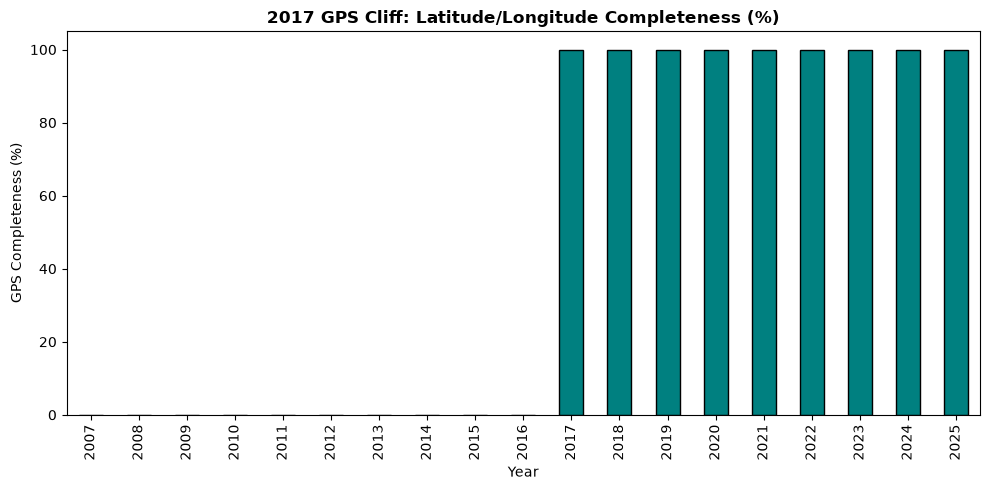

In [8]:
plt.figure(figsize=(10, 5))
gps_table["GPS present (%)"].plot(kind="bar", color="teal", edgecolor="black")
plt.title("2017 GPS Cliff: Latitude/Longitude Completeness (%)", fontsize=12, fontweight="bold")
plt.ylabel("GPS Completeness (%)")
plt.xlabel("Year")
plt.tight_layout()
plt.show()

GPS coordinates are 100% missing for 2007–2016 and 100% present from 2017 onwards: GPS recording only started in 2017. This is an important boundary: raw coordinates cannot be used as features across the full period.

### 3.3 Corrupted rows

In [9]:
nulls_per_row = df.isnull().sum(axis=1)
corrupted_rows = df[nulls_per_row > 10]
print(f"Corrupted Rows Found (>10 missing features): {len(corrupted_rows)}")
print("Corrupted Row Index:", corrupted_rows.index.tolist())
corrupted_rows[["date", "km", "Uphill", "Curve", "Bridge", "accident_classification"]]

Corrupted Rows Found (>10 missing features): 1
Corrupted Row Index: [57163]


,date,km,Uphill,Curve,Bridge,accident_classification
57163,2012-03-10,87.1,NaN,NaN,NaN,0


## 4. Concept drift: the 2015 e-DAT reporting change

We compare accident types per year to see whether reporting changed over time.

In [10]:
comparison = pd.DataFrame({
    year: df.loc[df["year"] == year, "accident_classification"].value_counts(normalize=True) * 100
    for year in (2007, 2025)
}).rename(index=CLASS_LABELS).round(2)
comparison.columns = ["2007 (%)", "2025 (%)"]
comparison

,2007 (%),2025 (%)
accident_classification,,
No Injuries (Class 0),59.46,15.50
Injuries (Class 1),36.74,77.54
Fatalities (Class 2),3.81,6.96


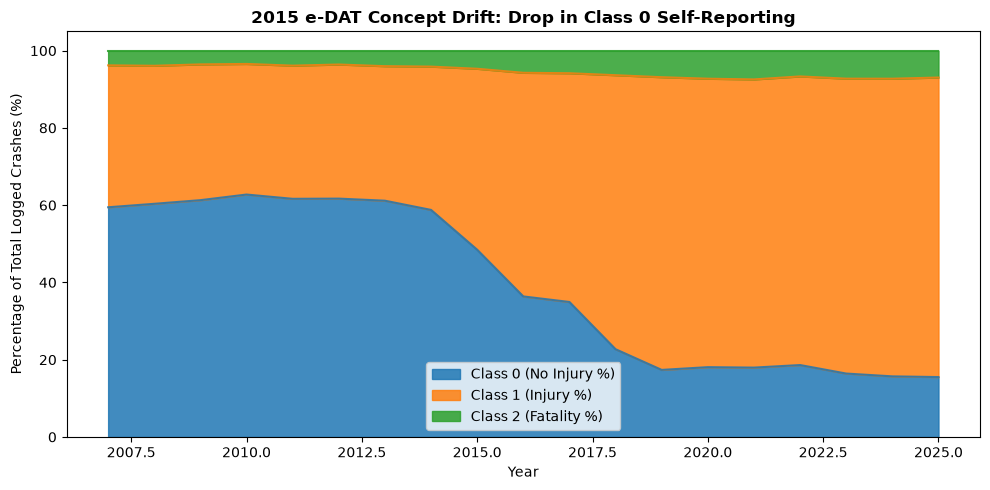

In [11]:
drift_table = pd.crosstab(df["year"], df["accident_classification"], normalize="index") * 100
drift_table.columns = ["Class 0 (No Injury %)", "Class 1 (Injury %)", "Class 2 (Fatality %)"]

plt.figure(figsize=(10, 5))
drift_table.plot(kind="area", stacked=True, alpha=0.85, ax=plt.gca())
plt.title("2015 e-DAT Concept Drift: Drop in Class 0 Self-Reporting", fontsize=12, fontweight="bold")
plt.ylabel("Percentage of Total Logged Crashes (%)")
plt.xlabel("Year")
plt.tight_layout()
plt.show()

Comparing 2007 to 2025 reveals a shift in recorded crash severity:
- Class 0 (no injuries) decreased from 59.5% to 15.5%
- Class 1 (injuries) increased from 36.7% to 77.5%
- Class 2 (fatalities) nearly doubled from 3.8% to 7.0%

This is **concept drift**. Around 2015, online self-reporting (e-DAT) redirected minor non-injury fender-benders away from manual police logging. Non-injury crashes "disappeared" from the official database, artificially inflating the share of severe crashes in recent years.

## 5. Fatality rate by feature

`is_fatal`: 1 = Fatal, 0 = Non-Fatal.

In [12]:
def fatality_rate(feature):
    summary = df.groupby(feature)["is_fatal"].agg(["count", "mean"])
    summary["fatality_rate_%"] = (summary["mean"] * 100).round(2)
    return summary


for feature, legend in [
    ("area_type", "0 = Rural, 1 = Urban"),
    ("time_of_day", "0 = Early Morning, 1 = Morning, 2 = Afternoon, 3 = Night"),
    ("Bridge", "0 = No, 1 = Yes"),
    ("Downhill", "0 = No, 1 = Yes"),
]:
    print(f"--- Fatality Rate by {feature} ({legend}) ---")
    print(fatality_rate(feature), end="\n\n")

--- Fatality Rate by area_type (0 = Rural, 1 = Urban) ---
           count      mean  fatality_rate_%
area_type                                  
0.0        75673  0.064766             6.48
1.0        74326  0.031227             3.12

--- Fatality Rate by time_of_day (0 = Early Morning, 1 = Morning, 2 = Afternoon, 3 = Night) ---
             count      mean  fatality_rate_%
time_of_day                                  
0            48806  0.034381             3.44
1            16955  0.085226             8.52
2            42907  0.033118             3.31
3            41332  0.064792             6.48

--- Fatality Rate by Bridge (0 = No, 1 = Yes) ---
         count      mean  fatality_rate_%
Bridge                                   
0.0     149620  0.047995             4.80
1.0        379  0.108179            10.82

--- Fatality Rate by Downhill (0 = No, 1 = Yes) ---
           count      mean  fatality_rate_%
Downhill                                   
0.0       146518  0.047093       

- **Area type:** rural highway crashes (6.48%) are more than twice as deadly as urban crashes (3.12%), possibly driven by higher speeds and longer emergency response times.
- **Time of day:** morning (8.52%) and night (6.48%) are the peak fatality periods, riskier than early morning (3.44%) or afternoon (3.31%).
- **Bridge:** bridge crashes are rare but over twice as lethal (10.82% vs. 4.80%).
- **Downhill:** downhill segments nearly double fatality risk (9.25% vs. 4.71%), a strong physical predictor for real-time dispatch triage.

## 6. Road infrastructure sparsity

In [13]:
INFRA_COLS = [
    "Straight", "Curve", "Crossing", "Downhill", "Uphill", "Road_Intersection", "Roundabout",
    "Regulated_Uturn", "Roadworks", "Overpass", "Bridge", "Temporary_Detour", "Tunnel",
]

infra_summary = pd.DataFrame({
    "Total Crashes": df[INFRA_COLS].sum().astype(int),
    "Prevalence (%)": (df[INFRA_COLS].mean() * 100).round(2),
}).sort_values(by="Total Crashes", ascending=False)
infra_summary

,Total Crashes,Prevalence (%)
Straight,105958,70.64
Curve,31319,20.88
Crossing,7098,4.73
Downhill,3481,2.32
Uphill,2694,1.80
Road_Intersection,2625,1.75
Roundabout,1009,0.67
Regulated_Uturn,858,0.57
Roadworks,677,0.45
Overpass,556,0.37


## 7. Data leakage audit

Which columns would really be known at call intake (t=0)? Road geometry, location markers and time context are all known when the call arrives. The target and anything derived from it must be excluded.

In [14]:
TARGET_COLS = ["accident_classification", "is_fatal"]
predictor_candidates = [col for col in df.columns if col not in TARGET_COLS]

print(f"Total Columns in Dataset: {len(df.columns)}")
print(f"Target Variables (must be excluded from predictors): {TARGET_COLS}")
print(f"\nPredictor Features Available at t=0 Intake ({len(predictor_candidates)} columns):")
for col in predictor_candidates:
    print(f"  [SAFE] {col}")

Total Columns in Dataset: 27
Target Variables (must be excluded from predictors): ['accident_classification', 'is_fatal']

Predictor Features Available at t=0 Intake (25 columns):
  [SAFE] date
  [SAFE] km
  [SAFE] road_direction
  [SAFE] roadway_type
  [SAFE] area_type
  [SAFE] latitude
  [SAFE] longitude
  [SAFE] time_of_day
  [SAFE] highway_type
  [SAFE] Uphill
  [SAFE] Crossing
  [SAFE] Curve
  [SAFE] Downhill
  [SAFE] Temporary_Detour
  [SAFE] Roadworks
  [SAFE] Road_Intersection
  [SAFE] Bridge
  [SAFE] Straight
  [SAFE] Regulated_Uturn
  [SAFE] Roundabout
  [SAFE] Tunnel
  [SAFE] Overpass
  [SAFE] year
  [SAFE] month
  [SAFE] day


**Audit verdict:** no post-crash operational fields (e.g. victim counts or damage scores) exist in this dataset. All predictor features reflect pre-existing road conditions or time context available at t=0.

**Caveats carried into Task 3:** although known at t=0, two groups of columns should not be used as raw features:
- `latitude` / `longitude`: missing for all of 2007–2016 (Section 3.2).
- `date` / `year`: because of the 2015 e-DAT change (Section 4), year mostly captures how crashes were logged, not road risk.

## 8. Summary of findings for data preparation

| Finding | Action |
|---|---|
| Target `is_fatal` is rare (4.81% overall) | Do not use accuracy; handle class imbalance |
| GPS missing for all of 2007–2016 | Exclude raw coordinates (or use a coarser location such as km marker) |
| 1 corrupted row (index 57163) | Drop |
| 90 missing `road_direction` values (0.06%) | Impute with the mode |
| 2015 e-DAT concept drift | Use an out-of-time split; do not use year as a feature |
| Very rare infrastructure flags (Tunnel, Temporary_Detour) | Consider grouping or dropping |
| No post-crash fields | No leakage from victim or damage data |

## 9. Data preparation (Samuel)

Turns the findings of Section 8 into model-ready data for the Task 3 notebook. Order matters: everything that **learns from the data** (imputation value, km cap, segment risk, encoders, scalers) is fitted on **Train only** and then applied to Validation and Test, so no information from the future leaks into training.

| Step | Operation |
|---|---|
| 9.1 | Cleaning: drop corrupted row, exclude GPS |
| 9.2 | Feature engineering: calendar features |
| 9.3 | Out-of-time split |
| 9.4 | Imputation, km cap, historical segment risk (fitted on Train) |
| 9.5 | Feature selection check on Validation |
| 9.6 | Encoding & scaling |
| 9.7 | Save prepared datasets for Task 3 |

In [15]:
import json

import joblib
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

### 9.1 Cleaning

- Drop corrupted row 57163 (Section 3.3).
- Exclude `latitude` / `longitude` (2017 GPS cliff, Section 3.2).
- Keep `date` / `year` only to split the data, never as predictors (2015 e-DAT drift, Section 4).

In [16]:
prep = df.drop(index=corrupted_rows.index).drop(columns=["latitude", "longitude"])
print(f"Rows after cleaning: {len(prep):,}")

Rows after cleaning: 149,999


### 9.2 Feature engineering: calendar features

The date of a crash is known at call intake. The dataset has no hour, only `time_of_day`, so rush-hour features are not possible.

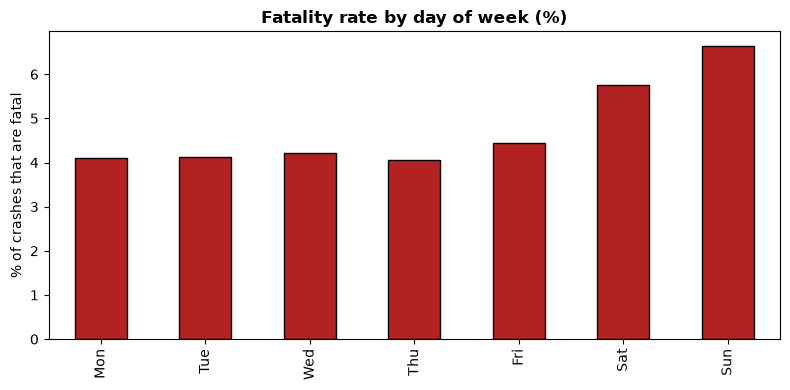

In [17]:
prep["day_of_week"] = prep["date"].dt.day_of_week  # 0 = Monday
prep["is_weekend"] = (prep["day_of_week"] >= 5).astype(int)
# Cyclical encoding: December and January are neighbours
prep["month_sin"] = np.sin(2 * np.pi * prep["month"] / 12)
prep["month_cos"] = np.cos(2 * np.pi * prep["month"] / 12)

weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
rate_by_day = prep.groupby("day_of_week")["is_fatal"].mean() * 100
rate_by_day.index = weekday_names

ax = rate_by_day.plot(kind="bar", color="firebrick", edgecolor="black", figsize=(8, 4))
ax.set_title("Fatality rate by day of week (%)", fontweight="bold")
ax.set_ylabel("% of crashes that are fatal")
plt.tight_layout()
plt.show()

Weekend crashes are clearly deadlier (about 5.8% on Saturday and 6.6% on Sunday vs. about 4.1% on weekdays).

### 9.3 Out-of-time split

Same split as the problem framing (Task 1): train on the past, evaluate on the most recent years. No random shuffling.

In [18]:
train = prep[prep["year"] <= 2021].copy()
val = prep[prep["year"].between(2022, 2023)].copy()
test = prep[prep["year"] >= 2024].copy()

pd.DataFrame({
    "Rows": [len(train), len(val), len(test)],
    "Fatal rate (%)": [s["is_fatal"].mean() * 100 for s in (train, val, test)],
}, index=["Train 2007-2021", "Validation 2022-2023", "Test 2024-2025"]).round(2)

,Rows,Fatal rate (%)
Train 2007-2021,130870,4.49
Validation 2022-2023,9073,6.97
Test 2024-2025,10056,7.11


The fatal rate is higher in Validation and Test than in Train, a consequence of the 2015 e-DAT reporting change. Ranking metrics (PR-AUC, Top-15%) are robust to this; predicted probabilities must be re-calibrated on Validation (done in Task 3).

### 9.4 Imputation, km cap and segment risk

**Imputation.** The 90 missing `road_direction` values are filled with the Train mode.

**km cap.** Six `km` values exceed 4,700 km (up to 8,280 km), longer than any Brazilian federal highway (BR-116, about 4,660 km). These are recording errors; `km_capped` caps them at 4,700 km and leaves all plausible values unchanged.

In [19]:
road_direction_mode = train["road_direction"].mode()[0]
KM_MAX = 4_700

for split in (train, val, test):
    split["road_direction"] = split["road_direction"].fillna(road_direction_mode)
    split["km_capped"] = split["km"].clip(upper=KM_MAX)

print(f"road_direction imputed with Train mode: {road_direction_mode:.0f}")
print(f"km capped at {KM_MAX:,} km; values above cap: {(prep['km'] > KM_MAX).sum()}")

road_direction imputed with Train mode: 1
km capped at 4,700 km; values above cap: 6


**Historical segment risk.** Dispatchers know some road stretches are black spots. Without GPS for the early years, a road segment is defined as highway type × 50 km band × area type, and its risk is the historical fatality rate of that segment **in the Train years**.

Two safeguards prevent leakage:
- **Out-of-fold on Train:** each Train crash gets the rate computed on the other 4 folds, so it never sees its own label.
- **Smoothing:** segments with few crashes are pulled towards the overall Train rate (weight of 50 crashes), so rare segments do not get extreme values.

Validation and Test use the rates from all of Train. Limitation: the dataset has no highway identifier, so a segment groups the same km band of all highways of one type.

In [20]:
SMOOTHING = 50


def add_segment(data):
    data["segment"] = (data["highway_type"].astype(int).astype(str) + "_"
                       + (data["km_capped"] // 50).astype(int).astype(str) + "_"
                       + data["area_type"].astype(int).astype(str))


def segment_rates(fit_data, prior):
    stats = fit_data.groupby("segment")["is_fatal"].agg(["sum", "count"])
    return (stats["sum"] + SMOOTHING * prior) / (stats["count"] + SMOOTHING)


for split in (train, val, test):
    add_segment(split)

train_prior = train["is_fatal"].mean()
train["segment_risk"] = train_prior
for fit_idx, apply_idx in KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(train):
    rates = segment_rates(train.iloc[fit_idx], train_prior)
    train.iloc[apply_idx, train.columns.get_loc("segment_risk")] = (
        train.iloc[apply_idx]["segment"].map(rates).fillna(train_prior).values)

full_train_rates = segment_rates(train, train_prior)
for split in (val, test):
    split["segment_risk"] = split["segment"].map(full_train_rates).fillna(train_prior)

print(f"{train['segment'].nunique()} segments in Train")
train["segment_risk"].describe().round(4)

218 segments in Train


count    130870.0000
mean          0.0443
std           0.0197
min           0.0113
25%           0.0264
50%           0.0418
75%           0.0603
max           0.1231
Name: segment_risk, dtype: float64

### 9.5 Feature selection check on Validation

Each candidate is added to the baseline feature set and scored with a balanced logistic regression trained on Train and evaluated on **Validation** (the Test set stays untouched for Task 3).

In [21]:
BASE_CATEGORICAL = ["roadway_type", "area_type", "time_of_day", "highway_type", "road_direction"]
BASE_NUMERIC = ["km"] + INFRA_COLS


def validation_score(categorical, numeric):
    model = Pipeline([
        ("prep", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
            ("num", StandardScaler(), numeric),
        ])),
        ("model", LogisticRegression(class_weight="balanced", max_iter=3000)),
    ])
    model.fit(train, train["is_fatal"])
    p = model.predict_proba(val)[:, 1]
    return {"PR-AUC": average_precision_score(val["is_fatal"], p),
            "ROC-AUC": roc_auc_score(val["is_fatal"], p)}


candidates = {
    "Baseline features": ([], []),
    "+ day_of_week, is_weekend": (["day_of_week"], ["is_weekend"]),
    "+ month_sin, month_cos": ([], ["month_sin", "month_cos"]),
    "+ km_capped (instead of km)": ([], ["km_capped"]),
    "+ segment_risk": ([], ["segment_risk"]),
    "All of the above": (["day_of_week"], ["is_weekend", "month_sin", "month_cos", "km_capped", "segment_risk"]),
}
selection = {}
for name, (extra_cat, extra_num) in candidates.items():
    numeric = BASE_NUMERIC + extra_num
    if "km_capped" in extra_num:
        numeric.remove("km")
    selection[name] = validation_score(BASE_CATEGORICAL + extra_cat, numeric)
pd.DataFrame(selection).T.round(4)

,PR-AUC,ROC-AUC
Baseline features,0.1234,0.6705
"+ day_of_week, is_weekend",0.1264,0.6711
"+ month_sin, month_cos",0.1235,0.6702
+ km_capped (instead of km),0.1234,0.6705
+ segment_risk,0.1264,0.6751
All of the above,0.1273,0.6739


Calendar features and segment risk both improve ranking on Validation. Monthly seasonality adds little for a linear model but is kept for tree-based models in Task 3. Grouping the rare infrastructure flags (Tunnel, Temporary_Detour, ...) was also tested and gave no gain, so the original flags are kept.

### 9.6 Encoding & scaling

One-hot encoding for categorical features, standard scaling for numeric features, both **fitted on Train only**. Tree-based models in Task 3 can skip this step and use the prepared columns directly.

In [22]:
CATEGORICAL = BASE_CATEGORICAL + ["day_of_week"]
NUMERIC = ["km_capped"] + INFRA_COLS + ["is_weekend", "month_sin", "month_cos", "segment_risk"]
FEATURES = CATEGORICAL + NUMERIC

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ("num", StandardScaler(), NUMERIC),
])
preprocessor.fit(train[FEATURES])

X_train_encoded = preprocessor.transform(train[FEATURES])
print(f"{len(FEATURES)} features -> {X_train_encoded.shape[1]} columns after one-hot encoding")

24 features -> 41 columns after one-hot encoding


### 9.7 Save prepared datasets for Task 3

Saved to `data/processed/` (not committed to git; rerun this notebook to regenerate):
- `train.csv`, `val.csv`, `test.csv`: baseline and engineered features, target `is_fatal`, and `year` for reference
- `features.json`: feature lists (baseline and full)
- `preprocessor.joblib`: encoder + scaler fitted on Train

In [23]:
OUT = DATA.parent.parent / "processed" if DATA.parent.name == "raw" else Path(".")
OUT.mkdir(parents=True, exist_ok=True)

columns = list(dict.fromkeys(BASE_CATEGORICAL + BASE_NUMERIC + FEATURES + ["is_fatal", "year"]))
for name, split in [("train", train), ("val", val), ("test", test)]:
    split[columns].to_csv(OUT / f"{name}.csv", index=False)

feature_lists = {
    "base_categorical": BASE_CATEGORICAL, "base_numeric": BASE_NUMERIC,
    "categorical": CATEGORICAL, "numeric": NUMERIC, "target": "is_fatal",
}
(OUT / "features.json").write_text(json.dumps(feature_lists, indent=2))
joblib.dump(preprocessor, OUT / "preprocessor.joblib")

print(f"Saved to {OUT.resolve()}:")
for f in sorted(OUT.glob("*")):
    if f.name != ".gitkeep":
        print(f"  {f.name}")

Saved to /Users/samuelbarrezueta/predictive-analytics-forecasting/data/processed:
  features.json
  preprocessor.joblib
  test.csv
  train.csv
  val.csv
